In [ ]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.utils.io import read_SIM_data
from IPython.display import display, SVG
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea
from matplotlib.ticker import FormatStrFormatter


COLOR_DICT = {
    "desmin": "#CC3311",
    "actin": "#0077BB",
    "actinin": "#009988",
    "myosin": "#BBBBBB",
}
DEFAULT_CROP_ZYX = (slice(0, 12), slice(2000 - 768, 2000), slice(0, 768))

datadir = Path("../../data/SIM")


In [ ]:
@dataclass
class PreparedOrthogonal:
    grids: dict
    crop_zyx: tuple
    spacing_xyz: tuple
    rotation_deg: float


@dataclass
class OrthogonalView:
    plane: str
    image: np.ndarray
    extent: tuple  # xmin,xmax,ymin,ymax OR xmin,xmax,zmin,zmax
    image_extent: tuple  # Actual viewport, including pixel-rounding padding
    world_bounds: tuple
    colors: dict


def prepare_orthogonal_pair(
    data_full,
    pixel_sizes,
    *,
    crop_zyx=DEFAULT_CROP_ZYX,
    desmin_channel=0,
    actinin_channel=1,
    rotation_deg=3.0,
):
    """Build and rotate the registered Desmin and alpha-actinin grids.

    Input arrays are C,Z,Y,X; pixel_sizes is (dz,dy,dx) in micrometers.
    crop_zyx is a tuple of three ordinary slices. Use None for the full volume.
    Grid origin is reset to (0,0,0) before rotation, matching the source code.
    No intensity normalization, flipping, or resampling is applied here.
    """
    import pyvista as pv

    data = np.asarray(data_full)
    spacing = np.asarray(pixel_sizes, dtype=float)
    if data.ndim != 4 or any(n == 0 for n in data.shape):
        raise ValueError("data_full must have nonempty C,Z,Y,X dimensions.")
    if spacing.shape != (3,) or not np.isfinite(spacing).all() or np.any(spacing <= 0):
        raise ValueError(
            "pixel_sizes must be positive finite (dz,dy,dx) in micrometers."
        )
    if desmin_channel == actinin_channel:
        raise ValueError("Choose distinct Desmin and alpha-actinin channels.")
    for channel in (desmin_channel, actinin_channel):
        if not 0 <= channel < data.shape[0]:
            raise ValueError("Channel index is outside data_full.")
    if not np.isfinite(rotation_deg):
        raise ValueError("rotation_deg must be finite.")
    if crop_zyx is None:
        crop_zyx = (slice(None),) * 3
    if len(crop_zyx) != 3:
        raise ValueError("crop_zyx must contain three slices in Z,Y,X order.")
    slices = []
    for sl, size in zip(crop_zyx, data.shape[1:]):
        if not isinstance(sl, slice) or sl.step not in (None, 1):
            raise ValueError(
                "Crop slices must have unit step; downsampling changes spacing."
            )
        start = 0 if sl.start is None else sl.start
        stop = size if sl.stop is None else sl.stop
        if not (
            isinstance(start, (int, np.integer))
            and isinstance(stop, (int, np.integer))
            and 0 <= start < stop <= size
        ):
            raise ValueError(f"Crop slice {sl} is outside axis length {size}.")
        slices.append(slice(int(start), int(stop)))
    slices = tuple(slices)
    grids = {}
    for name, channel in (("desmin", desmin_channel), ("actinin", actinin_channel)):
        volume = data[(channel,) + slices]
        if not np.issubdtype(volume.dtype, np.number) or not np.isfinite(volume).all():
            raise ValueError(f"{name}: expected finite numeric intensities.")
        xyz = volume.transpose(2, 1, 0)  # Same as rearrange(..., 'Z Y X -> X Y Z').
        grid = pv.ImageData(
            dimensions=np.array(xyz.shape) + 1, spacing=spacing[::-1], origin=(0, 0, 0)
        )
        grid.cell_data[name] = xyz.ravel(order="F")
        grids[name] = grid.rotate_z(float(rotation_deg), point=(0, 0, 0), inplace=False)
    return PreparedOrthogonal(grids, slices, tuple(spacing[::-1]), float(rotation_deg))


def load_orthogonal_pair(
    datadir,
    read_SIM_data,
    *,
    relative_path="alpha-actinin/Image2_SIM2.h5",
    **prepare_kwargs,
):
    """Use your existing experiment-specific reader."""
    data_full, pixel_sizes = read_SIM_data(Path(datadir) / relative_path)
    return prepare_orthogonal_pair(data_full, pixel_sizes, **prepare_kwargs)


def render_orthogonal_view(
    prepared,
    plane,
    *,
    width_px=1800,
    colors=None,
    clim=(0.0, 0.2),
    opacity=(0.0, 0.1, 0.8),
):
    """Render both rotated volumes, matching view_xy() or view_xz().

    XY looks from +Z with +Y up. XZ looks from -Y with +Z up, as in PyVista's
    view_xz(). Both cameras have identical horizontal world bounds and pixel
    width. The thin XZ view has a proportionally smaller screenshot height.
    Pixel-rounding padding is tracked explicitly, preserving calibration.
    """
    import pyvista as pv

    if plane not in ("xy", "xz"):
        raise ValueError("plane must be 'xy' or 'xz'.")
    width_px = int(width_px)
    if width_px < 2:
        raise ValueError("width_px must be at least 2.")
    colors = {**COLOR_DICT, **(colors or {})}
    limits = np.asarray(clim, dtype=float)
    alpha = np.asarray(opacity, dtype=float)
    if limits.shape != (2,) or not np.isfinite(limits).all() or limits[0] >= limits[1]:
        raise ValueError("clim must contain two increasing finite values.")
    if (
        alpha.ndim != 1
        or alpha.size < 2
        or not np.isfinite(alpha).all()
        or np.any((alpha < 0) | (alpha > 1))
    ):
        raise ValueError("opacity must contain at least two finite values in [0,1].")
    bounds = np.asarray(prepared.grids["desmin"].bounds, dtype=float)
    if not np.allclose(prepared.grids["actinin"].bounds, bounds):
        raise ValueError("Both registered volumes must have identical physical bounds.")
    x0, x1, y0, y1, z0, z1 = bounds
    dx, dy, dz = x1 - x0, y1 - y0, z1 - z0
    if min(dx, dy, dz) <= 0:
        raise ValueError("Volumes must have positive X, Y and Z extents.")
    cx, cy, cz = (x0 + x1) / 2, (y0 + y1) / 2, (z0 + z1) / 2
    low, high = (y0, y1) if plane == "xy" else (z0, z1)
    height_px = max(2, int(np.ceil(width_px * (high - low) / dx)))
    half_height = dx / 2 * height_px / width_px
    vertical_center = (low + high) / 2
    distance = 2 * max(dx, dy, dz)
    camera = (
        [(cx, cy, cz + distance), (cx, cy, cz), (0, 1, 0)]
        if plane == "xy"
        else [(cx, cy - distance, cz), (cx, cy, cz), (0, 0, 1)]
    )
    p = pv.Plotter(off_screen=True, window_size=(width_px, height_px))
    try:
        for name in ("desmin", "actinin"):
            actor = p.add_volume(
                prepared.grids[name],
                scalars=name,
                cmap=[colors[name]],
                opacity=alpha.tolist(),
                clim=tuple(limits),
                blending="maximum",
                show_scalar_bar=False,
                reset_camera=False,
            )
            actor.prop.interpolation_type = "linear"
        p.set_background("black")
        p.enable_parallel_projection()
        p.camera_position = camera
        p.camera.parallel_scale = half_height
        p.reset_camera_clipping_range()
        rgb = np.array(p.screenshot(transparent_background=False), copy=True)
    finally:
        p.close()
    return OrthogonalView(
        plane,
        rgb,
        (x0, x1, low, high),
        (x0, x1, vertical_center - half_height, vertical_center + half_height),
        tuple(bounds),
        colors,
    )


def render_orthogonal_pair(prepared, **render_kwargs):
    """Cache the XY/XZ screenshots so layout changes do not require rerendering."""
    return {
        plane: render_orthogonal_view(prepared, plane, **render_kwargs)
        for plane in ("xy", "xz")
    }


def compose_orthogonal_panel(
    views,
    *,
    panel_width=3.2,
    row_gap=0.14,
    figsize=None,
    margins=(0.70, 0.25, 0.62, 0.43),
    xticks=None,
    yticks=None,
    zticks=None,
    tick_format="%.1f",
    title_fontsize=14,
    title_pad=7,
    xtick_fontsize=10,
    ytick_fontsize=10,
    ztick_fontsize=10,
    xlabel_fontsize=13,
    ylabel_fontsize=13,
    zlabel_fontsize=13,
    xtick_pad=5,
    ytick_pad=7,
    ztick_pad=7,
    xlabel_pad=6,
    ylabel_pad=6,
    zlabel_pad=6,
    ytick_rotation=90,
    ztick_rotation=90,
    font_family="DejaVu Sans",
):
    """Stack XY above XZ at one shared physical scale, matching the reference.

    panel_width, row_gap, figsize and margins=(left,right,bottom,top) are inches.
    All fonts and *_pad are points. With figsize=None, width determines both
    panel heights from the calibrated extents. With explicit figsize, panels
    fit inside it without stretching either plane; surplus space is black.

    X ticks and limits are shared. Only the lower panel has numeric X labels.
    The XZ strip preserves the physical Z/X aspect ratio (no Z exaggeration).
    Negative X coordinates caused by rotation about the origin are retained.
    """
    xy, xz = views["xy"], views["xz"]
    if not np.allclose(xy.extent[:2], xz.extent[:2]):
        raise ValueError("The XY and XZ views must have identical X bounds.")
    x0, x1, y0, y1 = xy.extent
    _, _, z0, z1 = xz.extent
    dx, dy, dz = x1 - x0, y1 - y0, z1 - z0
    if min(dx, dy, dz) <= 0:
        raise ValueError("View extents must be positive.")
    left, right, bottom, top = map(float, margins)
    if min(left, right, bottom, top, row_gap) < 0 or panel_width <= 0:
        raise ValueError(
            "Margins/gap must be nonnegative; panel_width must be positive."
        )
    if figsize is None:
        xy_height, xz_height = panel_width * dy / dx, panel_width * dz / dx
        fw = left + panel_width + right
        fh = bottom + xz_height + row_gap + xy_height + top
        start_x, start_y = left, bottom
    else:
        fw, fh = map(float, figsize)
        available_w, available_h = fw - left - right, fh - bottom - top - row_gap
        if min(available_w, available_h) <= 0:
            raise ValueError("figsize is too small for the margins and gap.")
        panel_width = min(available_w, available_h * dx / (dy + dz))
        xy_height, xz_height = panel_width * dy / dx, panel_width * dz / dx
        start_x = left + (available_w - panel_width) / 2
        start_y = bottom + (available_h - xy_height - xz_height) / 2
    tx = np.linspace(x0, x1, 5) if xticks is None else np.asarray(xticks)
    ty = np.linspace(y0, y1, 5) if yticks is None else np.asarray(yticks)
    tz = np.array([z0, z1]) if zticks is None else np.asarray(zticks)
    with (
        plt.style.context("default"),
        mpl.rc_context(
            {
                "font.family": font_family,
                "figure.autolayout": False,
                "figure.constrained_layout.use": False,
                "text.usetex": False,
            }
        ),
    ):
        fig = plt.figure(figsize=(fw, fh), facecolor="black")
        ax_xy = fig.add_axes(
            [
                start_x / fw,
                (start_y + xz_height + row_gap) / fh,
                panel_width / fw,
                xy_height / fh,
            ],
            facecolor="black",
        )
        ax_xz = fig.add_axes(
            [start_x / fw, start_y / fh, panel_width / fw, xz_height / fh],
            facecolor="black",
            sharex=ax_xy,
        )
        for ax, view, ticks, fontsize, pad, rotation in (
            (ax_xy, xy, ty, ytick_fontsize, ytick_pad, ytick_rotation),
            (ax_xz, xz, tz, ztick_fontsize, ztick_pad, ztick_rotation),
        ):
            ax.imshow(
                view.image,
                extent=view.image_extent,
                origin="upper",
                interpolation="none",
                aspect="equal",
            )
            ax.set_xticks(tx)
            ax.set_yticks(ticks)
            ax.set_xlim(x0, x1)
            ax.set_ylim(*view.extent[2:])
            ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
            ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))
            ax.tick_params(colors="white", direction="in", length=3, width=0.7)
            ax.tick_params(axis="x", labelsize=xtick_fontsize, pad=xtick_pad)
            ax.tick_params(
                axis="y", labelsize=fontsize, pad=pad, labelrotation=rotation
            )
            for side, spine in ax.spines.items():
                spine.set_visible(side in ("left", "bottom"))
                spine.set_color("#AAAAAA")
                spine.set_linewidth(0.7)
            for label in ax.get_xticklabels():
                label.set_ha("center")
            for value, label in zip(ax.get_yticks(), ax.get_yticklabels()):
                label.set_va(
                    "bottom" if np.isclose(value, view.extent[2]) else "center"
                )
        ax_xy.tick_params(axis="x", labelbottom=False)
        ax_xy.set_ylabel(
            "y (μm)", color="white", fontsize=ylabel_fontsize, labelpad=ylabel_pad
        )
        ax_xz.set_ylabel(
            "z (μm)", color="white", fontsize=zlabel_fontsize, labelpad=zlabel_pad
        )
        ax_xz.set_xlabel(
            "x (μm)", color="white", fontsize=xlabel_fontsize, labelpad=xlabel_pad
        )

        words = [
            ("Desmin", xy.colors["desmin"]),
            (" / ", "white"),
            ("α-actinin", xy.colors["actinin"]),
        ]
        packed = HPacker(
            children=[
                TextArea(word, textprops={"color": color, "fontsize": title_fontsize})
                for word, color in words
            ],
            align="center",
            pad=0,
            sep=0,
        )
        header = AnchoredOffsetbox(
            loc="lower center",
            child=packed,
            frameon=False,
            pad=0,
            borderpad=title_pad / title_fontsize,
            bbox_to_anchor=(0.5, 1),
            bbox_transform=ax_xy.transAxes,
            prop={"size": title_fontsize},
        )
        header.set_clip_on(False)
        ax_xy.add_artist(header)
    return fig, (ax_xy, ax_xz)

In [23]:
prepared = load_orthogonal_pair(
    datadir,
    read_SIM_data,
    relative_path="alpha-actinin/Image2_SIM2.h5",
    crop_zyx=(
        slice(0, 12),
        slice(2000 - 768, 2000),
        slice(0, 768),
    ),
    rotation_deg=3,
)

In [ ]:
# Render once; reuse views when adjusting the layout.
views = render_orthogonal_pair(
    prepared,
    width_px=1800,  # Same horizontal resolution for both views
    colors=COLOR_DICT,
    clim=(0, 0.2),
    opacity=(0.0, 0.1, 0.8),
)

In [ ]:
fig, (ax_xy, ax_xz) = compose_orthogonal_panel(
    views,
    panel_width=4.0,  # Inches
    row_gap=0.25,  # Gap between XY and XZ, in inches
    figsize=None,  # Alternatively: (4.5, 5.5)
    margins=(0.70, 0.25, 0.62, 0.43),  # Left, right, bottom, top
    title_fontsize=16,
    xtick_fontsize=13,
    ytick_fontsize=13,
    ztick_fontsize=13,
    xlabel_fontsize=15,
    ylabel_fontsize=15,
    zlabel_fontsize=15,
    xlabel_pad=6,
    ylabel_pad=6,
    zlabel_pad=6,
)

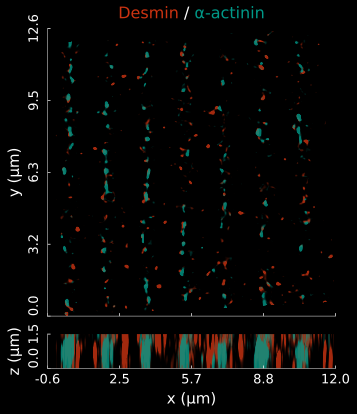

In [38]:
savepath = "../../figures/4b"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)